In [1]:
!pip install -q tensorflow opencv-python scikit-learn seaborn

In [37]:
import zipfile
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import tensorflow as tf
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import RandomTranslation
from tensorflow.keras.layers import (Input,Conv2D,MaxPooling2D,Flatten,Dense,Dropout,BatchNormalization,RandomRotation,RandomZoom)
from tensorflow.keras.callbacks import (EarlyStopping,ModelCheckpoint,ReduceLROnPlateau)

In [3]:
from google.colab import drive
drive.mount('/content/drive')
DATA_DIR = "/content/drive/MyDrive/Data"
print("Dataset exists:", os.path.exists(DATA_DIR))
print("Available classes:", os.listdir(DATA_DIR))

Mounted at /content/drive
Dataset exists: True
Available classes: ['A', 'B', 'D', 'E', 'F', 'N', 'C', 'O', 'M', 'K', 'H', 'G', 'P', 'L', 'I', 'Q', 'S', 'T', 'W', 'X', 'V', 'Y', 'R', 'U']


In [4]:
classes = sorted([folder for folder in os.listdir(DATA_DIR)if os.path.isdir(os.path.join(DATA_DIR, folder))])
num_classes = len(classes)
print("Total Classes:", num_classes)
print("Classes:", classes)

Total Classes: 24
Classes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']


In [5]:
class_counts = {}
for class_name in classes:
    folder_path = os.path.join(DATA_DIR, class_name)
    images = [file for file in os.listdir(folder_path)if file.lower().endswith(('.jpg', '.jpeg', '.png'))]
    class_counts[class_name] = len(images)
df = pd.DataFrame(list(class_counts.items()),columns=['Sign', 'Image_Count'])
print(df)
print("\nTotal Images:", df['Image_Count'].sum())

   Sign  Image_Count
0     A          242
1     B          259
2     C          247
3     D          147
4     E          243
5     F          226
6     G          241
7     H          116
8     I          179
9     K          245
10    L          182
11    M          235
12    N          237
13    O          229
14    P          234
15    Q          216
16    R          211
17    S          229
18    T          216
19    U          135
20    V          122
21    W          128
22    X          202
23    Y          251

Total Images: 4972


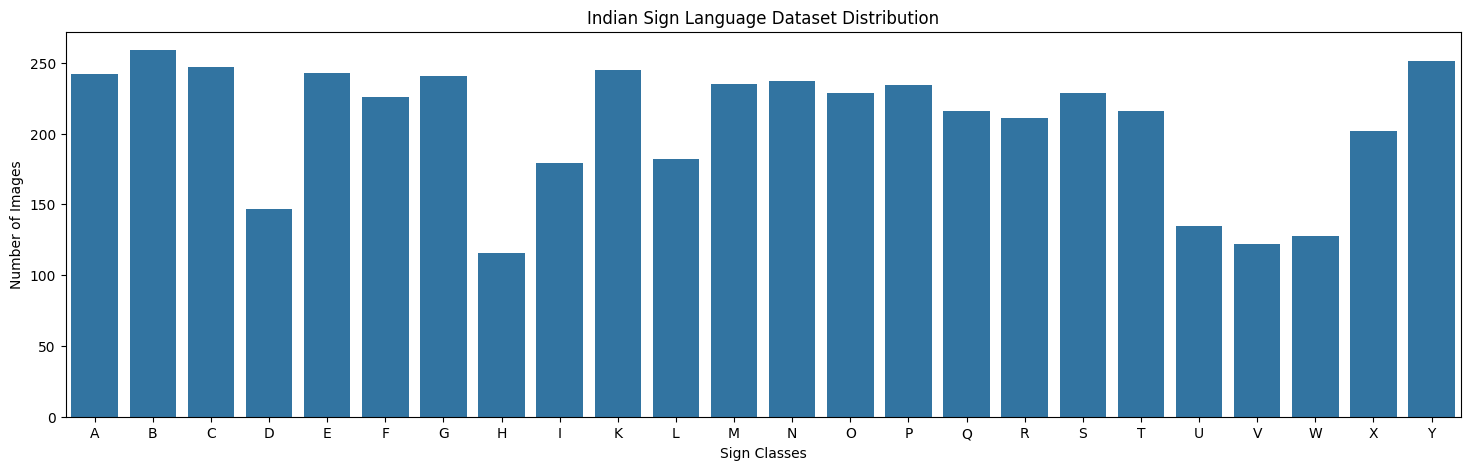

In [6]:
plt.figure(figsize=(18, 5))
sns.barplot(data=df,x='Sign',y='Image_Count')
plt.title("Indian Sign Language Dataset Distribution")
plt.xlabel("Sign Classes")
plt.ylabel("Number of Images")
plt.show()

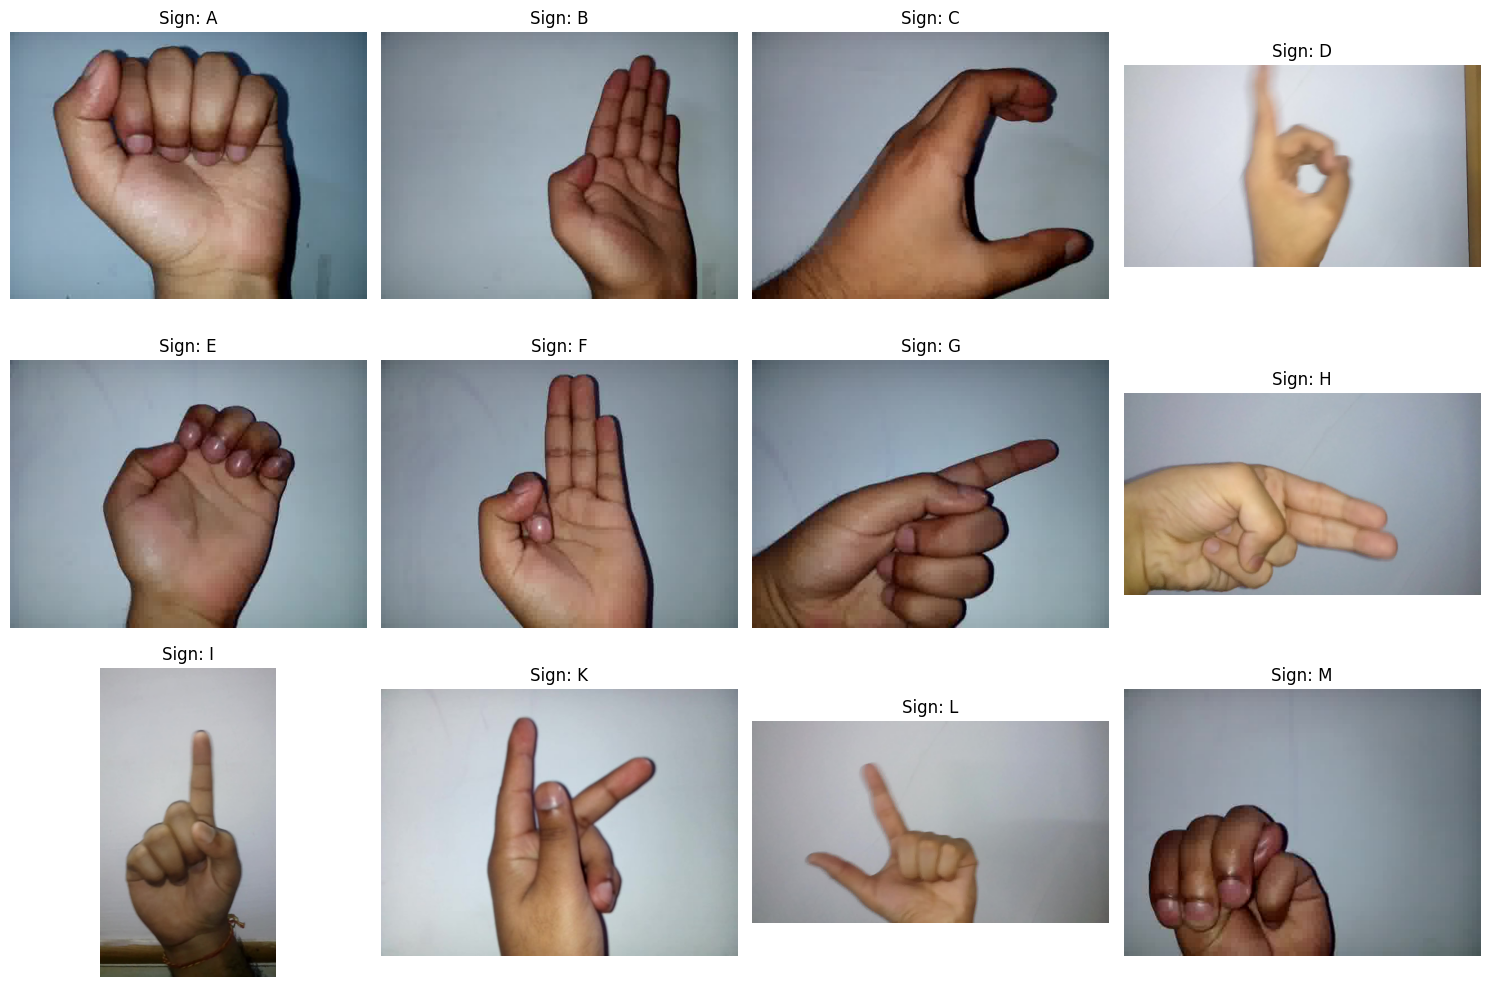

In [7]:
plt.figure(figsize=(15, 10))
for i, class_name in enumerate(classes[:12]):
    folder_path = os.path.join(DATA_DIR, class_name)
    image_files = [f for f in os.listdir(folder_path)if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    image_file = random.choice(image_files)
    image_path = os.path.join(folder_path, image_file)
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title("Sign: " + class_name)
    plt.axis('off')
plt.tight_layout()
plt.show()

In [8]:
image_paths = []
image_labels = []
for label, class_name in enumerate(classes):
    folder_path = os.path.join(DATA_DIR, class_name)
    for file_name in os.listdir(folder_path):
        if file_name.lower().endswith(('.jpg', '.jpeg', '.png')):
            image_path = os.path.join(folder_path, file_name)
            image_paths.append(image_path)
            image_labels.append(label)
image_paths = np.array(image_paths)
image_labels = np.array(image_labels)
print("Total Images:", len(image_paths))
print("Total Labels:", len(image_labels))

Total Images: 4972
Total Labels: 4972


In [9]:
X_train, X_temp, y_train, y_temp = train_test_split(image_paths,image_labels,test_size=0.30,random_state=42,stratify=image_labels)
X_val, X_test, y_val, y_test = train_test_split(X_temp,y_temp,test_size=0.50,random_state=42,stratify=y_temp)
print("Training Images:", len(X_train))
print("Validation Images:", len(X_val))
print("Testing Images:", len(X_test))

Training Images: 3480
Validation Images: 746
Testing Images: 746


In [10]:
IMG_SIZE = 64
BATCH_SIZE = 32
def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_image(image,channels=3,expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image,[IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

In [11]:
def create_dataset(paths, labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(load_image,num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        dataset = dataset.shuffle(buffer_size=len(paths),seed=42)
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset
train_ds = create_dataset( X_train, y_train, training=True)
val_ds = create_dataset(X_val, y_val)
test_ds = create_dataset(X_test, y_test)

In [12]:
model = Sequential([
    Input(shape=(64, 64, 3)),
    RandomRotation(0.05),
    RandomZoom(0.10),
    RandomTranslation(0.05, 0.05),
    Conv2D(32, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Conv2D(128, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation                 │ (None, 64, 64, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 64, 64, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 62, 62, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 29, 29, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │         3,096 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 687,192 (2.62 MB)

 Trainable params: 686,744 (2.62 MB)

 Non-trainable params: 448 (1.75 KB)

In [13]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])


In [14]:
early_stop = EarlyStopping(monitor='val_loss',patience=6,restore_best_weights=True)
checkpoint = ModelCheckpoint('/content/best_isl_model.keras',monitor='val_accuracy',save_best_only=True,mode='max')
reduce_lr = ReduceLROnPlateau(monitor='val_loss',factor=0.5,patience=3,min_lr=0.00001)
callbacks = [early_stop,checkpoint,reduce_lr]

In [15]:
history = model.fit(train_ds,validation_data=val_ds,epochs=30,callbacks=callbacks)

Epoch 1/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 742s 1s/step - accuracy: 0.4437 - loss: 2.0057 - val_accuracy: 0.0804 - val_loss: 8.7742 - learning_rate: 0.0010
Epoch 2/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - accuracy: 0.6920 - loss: 0.9860 - val_accuracy: 0.0416 - val_loss: 15.6486 - learning_rate: 0.0010
Epoch 3/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.8060 - loss: 0.6023 - val_accuracy: 0.0831 - val_loss: 11.4547 - learning_rate: 0.0010
Epoch 4/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 28s 51ms/step - accuracy: 0.8491 - loss: 0.4650 - val_accuracy: 0.3673 - val_loss: 4.3590 - learning_rate: 0.0010
Epoch 5/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 11s 38ms/step - accuracy: 0.8885 - loss: 0.3721 - val_accuracy: 0.7547 - val_loss: 0.9934 - learning_rate: 0.0010
Epoch 6/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - accuracy: 0.9083 - loss: 0.3110 - val_accuracy: 0.6354 - val_loss: 1.7133 - learning_rate: 0.0010
Epoch 7/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 21s 30ms/step - accuracy: 0.9181 - 

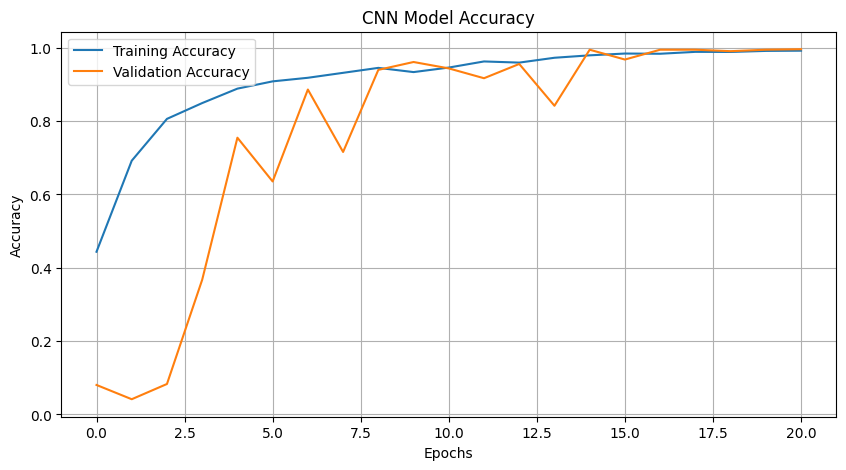

In [16]:
plt.figure(figsize=(10, 5))
plt.plot(history.history['accuracy'],label='Training Accuracy')
plt.plot(history.history['val_accuracy'],label='Validation Accuracy')
plt.title("CNN Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

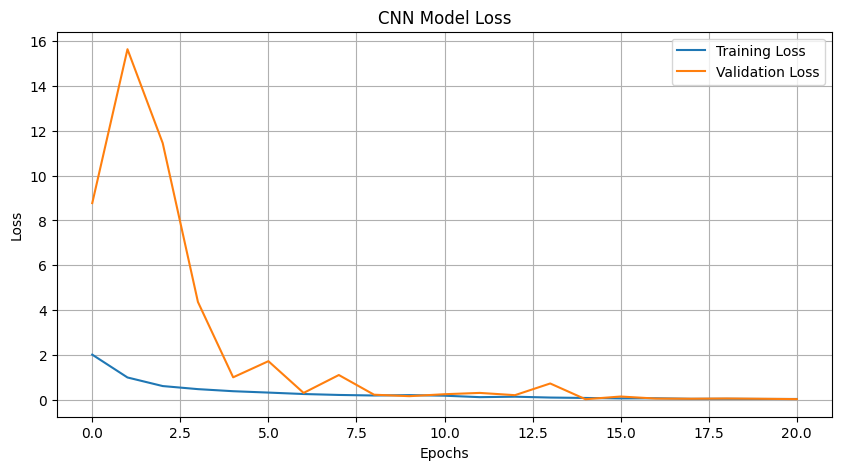

In [17]:
plt.figure(figsize=(10, 5))
plt.plot( history.history['loss'],label='Training Loss')
plt.plot(history.history['val_loss'],label='Validation Loss')
plt.title("CNN Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

In [18]:
best_model = tf.keras.models.load_model('/content/best_isl_model.keras')
test_loss, test_accuracy = best_model.evaluate(test_ds)
print("Test Loss:", test_loss)
print("Test Accuracy:",round(test_accuracy * 100, 2),"%")

24/24 ━━━━━━━━━━━━━━━━━━━━ 127s 5s/step - accuracy: 1.0000 - loss: 6.3349e-04
Test Loss: 0.0006334942881949246
Test Accuracy: 100.0 %


In [19]:
y_true = []
y_pred = []
for images, labels in test_ds:
    predictions = best_model.predict(images,verbose=0)
    predicted_labels = np.argmax(predictions,axis=1)
    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)
y_true = np.array(y_true)
y_pred = np.array(y_pred)
print("Predictions generated successfully!")

Predictions generated successfully!


In [20]:
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score( y_true,y_pred,average='weighted',zero_division=0)
recall = recall_score(y_true,y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_true,y_pred,average='weighted',zero_division=0)
results = pd.DataFrame({
    'Model': ['CNN'],
    'Accuracy': [accuracy],
    'Precision': [precision],
    'Recall': [recall],
    'F1 Score': [f1]})
print(results)

  Model  Accuracy  Precision  Recall  F1 Score
0   CNN       1.0        1.0     1.0       1.0


              precision    recall  f1-score   support

           A       1.00      1.00      1.00        36
           B       1.00      1.00      1.00        39
           C       1.00      1.00      1.00        37
           D       1.00      1.00      1.00        22
           E       1.00      1.00      1.00        36
           F       1.00      1.00      1.00        34
           G       1.00      1.00      1.00        36
           H       1.00      1.00      1.00        17
           I       1.00      1.00      1.00        27
           K       1.00      1.00      1.00        37
           L       1.00      1.00      1.00        28
           M       1.00      1.00      1.00        35
           N       1.00      1.00      1.00        36
           O       1.00      1.00      1.00        34
           P       1.00      1.00      1.00        35
           Q       1.00      1.00      1.00        33
           R       1.00      1.00      1.00        32
           S       1.00    

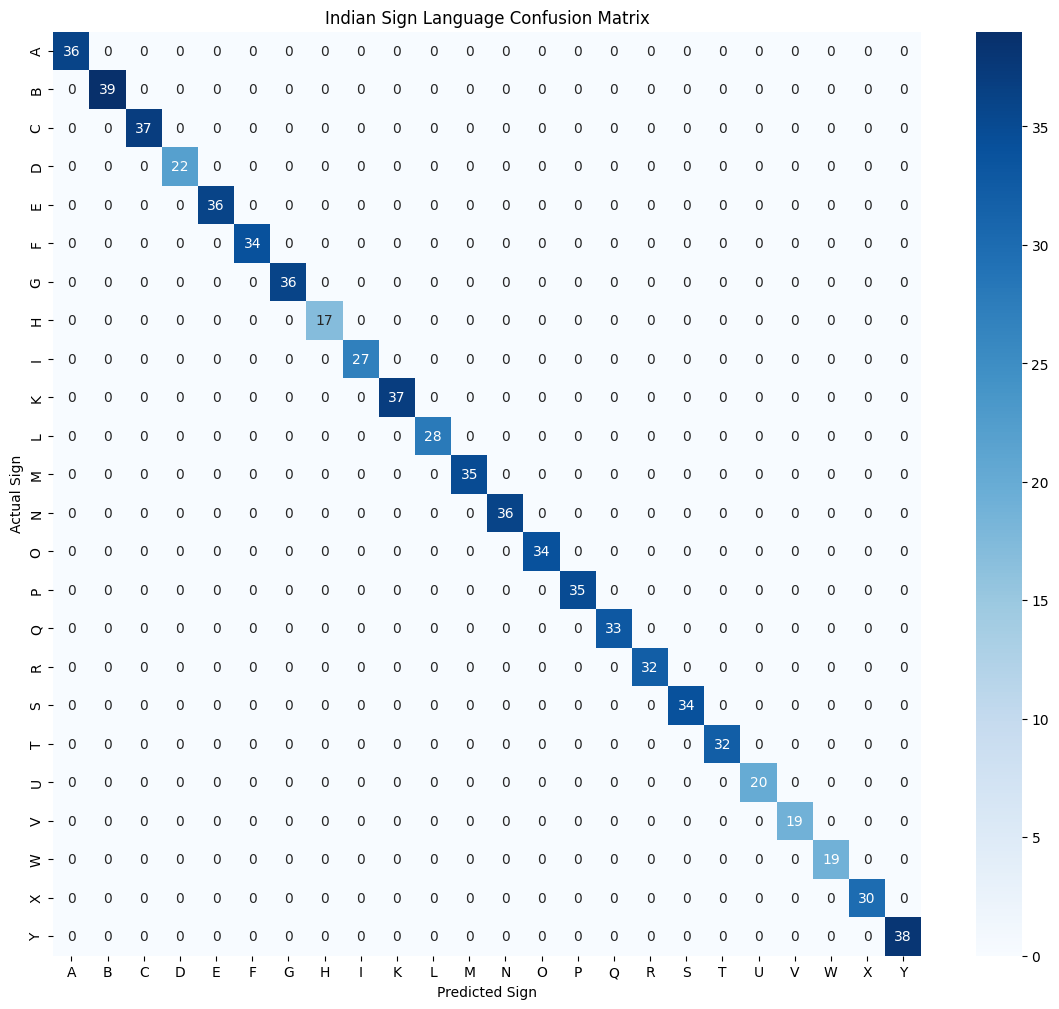

In [21]:
print(classification_report(y_true,y_pred,labels=np.arange(num_classes),target_names=classes,zero_division=0))
cm = confusion_matrix(y_true, y_pred, labels=np.arange(num_classes))
plt.figure(figsize=(14, 12))
sns.heatmap( cm, annot=True, fmt='d', cmap='Blues',xticklabels=classes,yticklabels=classes)
plt.title("Indian Sign Language Confusion Matrix")
plt.xlabel("Predicted Sign")
plt.ylabel("Actual Sign")
plt.show()

In [35]:
from google.colab import files
uploaded_image = files.upload()
image_path = list(uploaded_image.keys())[0]
print("Uploaded Image:", image_path)

Saving 154.jpg to 154.jpg
Uploaded Image: 154.jpg


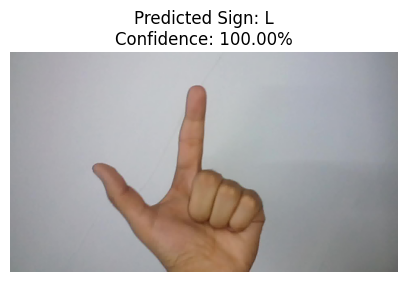

Predicted Sign: L
Confidence: 100.0 %


'L'

In [36]:
def predict_sign(image_path):
    image = cv2.imread(image_path)
    if image is None:
        raise ValueError("Unable to read image!")
    image_rgb = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
    resized = cv2.resize(image_rgb,(64, 64))
    normalized = resized.astype( np.float32) / 255.0
    input_image = np.expand_dims(normalized, axis=0)
    prediction = best_model.predict( input_image,  verbose=0)
    predicted_index = np.argmax(prediction)
    predicted_sign = classes[predicted_index]
    confidence = prediction[0][predicted_index] * 100
    plt.figure(figsize=(5, 5))
    plt.imshow(image_rgb)
    plt.title( f"Predicted Sign: {predicted_sign}\n" f"Confidence: {confidence:.2f}%")
    plt.axis('off')
    plt.show()
    print("Predicted Sign:", predicted_sign)
    print("Confidence:", round(float(confidence), 2), "%")
    return predicted_sign
predict_sign(image_path)

# **Problems**


1.   Different image sizes
2.   Limited dataset size
3.   Model overfitting
4.   Incorrect sign predictions





# **Solutions**

1.   Resized all images to 64 × 64 pixels.
2.   Normalized pixel values between 0 and 1.
3.   Applied Dropout and Batch Normalization.
4.   Evaluated performance using a confusion matrix and classification report.



# **Conclusions**
Sign Language Recognition project successfully demonstrates the use of Deep Learning and Convolutional Neural Networks (CNN) to recognize and classify Indian Sign Language alphabet signs from images.
The model learns visual patterns from hand gestures and predicts the corresponding sign. This project highlights the potential of AI in improving communication accessibility for the deaf and hard-of-hearing community. It can be further enhanced to recognize real-time gestures and complete sign-language sentences.